# 🌿 Deep Learning-Based Plant Disease Detection
### End-to-End Foliar Disease Classification in Potato & Tomato Crops using MobileNetV2 Transfer Learning
---

## 📌 Project Overview
Plant diseases pose a severe threat to global food security and agricultural productivity. Early and accurate diagnosis enables farmers and agronomists to apply targeted remedies before crop loss becomes irreversible.

In this notebook, we develop an advanced, end-to-end **Convolutional Neural Network (CNN)** classifier using **Transfer Learning with MobileNetV2** entirely inside Jupyter Notebook. We focus on **6 high-impact disease categories** across Tomato and Potato crops from the benchmark **PlantVillage** dataset.

### 🎯 Target Categories
| # | Class Name | Crop | Condition | Pathogen / Cause | Characteristic Symptoms |
|---|---|---|---|---|---|
| 1 | `Potato___Early_blight` | Potato | Diseased | *Alternaria solani* (Fungus) | Concentric target-like brown spots on mature leaves |
| 2 | `Potato___Late_blight` | Potato | Diseased | *Phytophthora infestans* (Oomycete) | Water-soaked dark lesions, white fungal bloom in humidity |
| 3 | `Potato___healthy` | Potato | Healthy | None (Optimal foliage) | Uniform green canopy, intact cellular structure |
| 4 | `Tomato___Early_blight` | Tomato | Diseased | *Alternaria solani* (Fungus) | Dark brown rings with yellow halo, premature defoliation |
| 5 | `Tomato___Late_blight` | Tomato | Diseased | *Phytophthora infestans* (Oomycete) | Rapidly spreading dark brown greasy patches, stem necrosis |
| 6 | `Tomato___healthy` | Tomato | Healthy | None (Optimal foliage) | Robust leaf margins, healthy photosynthetic tissue |

---

## 🏗️ Architecture & Pipeline Flow
1. **Environment Setup & Diagnostics**: TensorFlow 2.x, GPU/CPU runtime checks, random seed fixing.
2. **Hyperparameters & Configuration**: Standardized dimensions, batching, and dual-phase learning rates.
3. **Automated Dataset Verification**: Resilient dataset verification and automated downloader.
4. **Exploratory Data Analysis (EDA)**: Class balance inspection, metadata extraction, and Seaborn visual summary.
5. **Sample Leaf Inspection**: High-resolution visualization of healthy vs. infected leaf samples.
6. **Data Preprocessing & Splitting**: Splitting into Train (70%), Validation (15%), and Test (15%) with `AUTOTUNE` prefetching.
7. **Data Augmentation**: Robust rotational, zooming, flipping, and contrast transformations to eliminate overfitting.
8. **Transfer Learning with MobileNetV2**: Pre-trained ImageNet backbone with custom classification head.
9. **Two-Stage Training**:
   - **Phase 1 (Feature Extraction)**: Training top classification head with base model frozen.
   - **Phase 2 (Fine-Tuning)**: Unfreezing top backbone layers with a micro learning rate ($10^{-5}$).
10. **Model Evaluation & Diagnostics**: Accuracy, Precision, Recall, F1-Score, and Seaborn Confusion Matrix.
11. **Training Curve Visualization**: Side-by-side progression of loss and accuracy across training phases.
12. **Inference Pipeline & Agronomic Remedies**: Predicting disease on novel leaves with confidence scores and organic/chemical action plans.
13. **Model & Metadata Export**: Saving standalone `.keras` and JSON label mapping for production deployment.


## 1. Environment Setup & Library Imports
We load all essential libraries required for computer vision, deep learning, numerical processing, and evaluation metrics:
- **TensorFlow & Keras**: Model architecture, transfer learning backbone, data pipelines, and callbacks.
- **NumPy & Pandas**: Array manipulations, dataset structuring, and metric summarization.
- **Matplotlib & Seaborn**: High-resolution publication-quality graphs and confusion matrix heatmaps.
- **Scikit-learn**: Precision, recall, F1-score, and confusion matrix computation.
- **Pillow (PIL)**: High-speed image loading, inspection, and verification.


In [1]:
# Suppress redundant C++ warnings from TensorFlow for clean notebook output
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import sys
import glob
import json
import time
import random
import warnings
from pathlib import Path

# Numerical & Data Handling
import numpy as np
import pandas as pd
from PIL import Image

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Deep Learning Framework
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, optimizers

# Evaluation Metrics
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from IPython.display import display

warnings.filterwarnings('ignore')

# Set random seeds for absolute reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Verify Environment & Hardware Diagnostics
print("=" * 65)
print(f"🐍 Python Version     : {sys.version.split()[0]}")
print(f"🧠 TensorFlow Version : {tf.__version__}")
print(f"📊 NumPy Version      : {np.__version__}")
print(f"🐼 Pandas Version     : {pd.__version__}")
print(f"🖼️ Pillow Version     : {Image.__version__}")

# GPU Runtime Check
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"🚀 Acceleration Engine: GPU Detected ({len(gpus)} device(s)) -> {gpus[0].name}")
else:
    print("💻 Acceleration Engine: CPU Mode (Highly optimized with oneDNN)")
print("=" * 65)


🐍 Python Version     : 3.14.0
🧠 TensorFlow Version : 2.22.0-rc0
📊 NumPy Version      : 2.4.4
🐼 Pandas Version     : 3.0.2
🖼️ Pillow Version     : 12.2.0


💻 Acceleration Engine: CPU Mode (Highly optimized with oneDNN)


## 2. Hyperparameters & Global Configuration
Centralizing configuration parameters ensures modularity, repeatability, and easy experimentation.
- **Image Resolution**: $224 \times 224 \times 3$, the native resolution of MobileNetV2.
- **Batch Size**: 16, balancing gradient stability and memory footprint.
- **Dual-Phase Learning Rates**: $10^{-3}$ for rapid feature head adaptation, followed by $10^{-5}$ for gentle fine-tuning.


In [2]:
# Image & Pipeline Parameters
IMAGE_WIDTH = 224
IMAGE_HEIGHT = 224
IMAGE_SIZE = (IMAGE_HEIGHT, IMAGE_WIDTH)
CHANNELS = 3
BATCH_SIZE = 16

# Training Hyperparameters
EPOCHS_PHASE1 = 8          # Feature extraction (frozen base)
EPOCHS_PHASE2 = 4          # Fine-tuning (top layers unfrozen)
INITIAL_LR = 1e-3          # Initial learning rate for classifier head
FINE_TUNE_LR = 1e-5        # Low learning rate to protect pre-trained weights

# File System Directories
DATASET_DIR = "dataset"
EXPORT_DIR = "saved_models"
MODEL_FILENAME = "plant_disease_mobilenetv2.keras"
CLASS_INDICES_FILENAME = "class_indices.json"

# Plotting & Visualization Settings
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
sns.set_theme(style='whitegrid', palette='muted')

print("✅ Configuration and Hyperparameters initialized successfully.")


✅ Configuration and Hyperparameters initialized successfully.


## 3. Dataset Verification & Automated Acquisition Helper
This cell verifies that the required 6 PlantVillage categories are present in the `dataset` directory:
1. `Potato___Early_blight`
2. `Potato___Late_blight`
3. `Potato___healthy`
4. `Tomato___Early_blight`
5. `Tomato___Late_blight`
6. `Tomato___healthy`

If the folder is not found or empty (e.g., when running on a fresh machine or Google Colab), the script includes an automated downloader that retrieves genuine PlantVillage images directly from the official PlantVillage repository, ensuring the notebook executes smoothly end-to-end.


In [3]:
import urllib.request
from concurrent.futures import ThreadPoolExecutor

TARGET_CLASSES = [
    'Potato___Early_blight',
    'Potato___Late_blight',
    'Potato___healthy',
    'Tomato___Early_blight',
    'Tomato___Late_blight',
    'Tomato___healthy'
]

def verify_or_download_dataset(data_dir=DATASET_DIR, samples_per_class=50):
    """
    Verifies that the target 6 classes exist with valid leaf images.
    If missing, automatically downloads a starter set from the official PlantVillage repository.
    """
    os.makedirs(data_dir, exist_ok=True)
    all_present = True
    counts = {}

    for cls in TARGET_CLASSES:
        cls_path = os.path.join(data_dir, cls)
        if not os.path.exists(cls_path):
            all_present = False
            counts[cls] = 0
        else:
            valid_imgs = [f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
            counts[cls] = len(valid_imgs)
            if len(valid_imgs) < 10:
                all_present = False

    if all_present:
        print("✅ Local PlantVillage dataset verified! Class image counts:")
        for cls, count in counts.items():
            print(f"   📂 {cls:<28} : {count} images")
        return True

    print("⚠️ Dataset incomplete or missing locally. Initiating automated download from PlantVillage repository...")
    base_api = "https://api.github.com/repos/spMohanty/PlantVillage-Dataset/contents/raw/color/"
    
    def download_img(item, dest):
        try:
            if not os.path.exists(dest):
                urllib.request.urlretrieve(item['download_url'], dest)
            return True
        except Exception:
            return False

    for cls in TARGET_CLASSES:
        cls_dir = os.path.join(data_dir, cls)
        os.makedirs(cls_dir, exist_ok=True)
        try:
            req = urllib.request.Request(base_api + cls, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=15) as resp:
                items = json.loads(resp.read().decode())
            valid_items = [it for it in items if it['name'].lower().endswith(('.jpg', '.jpeg', '.png'))][:samples_per_class]
            print(f"   ⬇️ Downloading {len(valid_items)} images for {cls}...")
            with ThreadPoolExecutor(max_workers=8) as executor:
                futures = [executor.submit(download_img, it, os.path.join(cls_dir, it['name'])) for it in valid_items]
                [f.result() for f in futures]
            print(f"   ✅ Finished {cls} ({len(os.listdir(cls_dir))} images)")
        except Exception as err:
            print(f"   ❌ Could not download {cls}: {err}")

    print("\n🎉 Dataset check complete.")
    return True

# Run dataset verification
verify_or_download_dataset()


✅ Local PlantVillage dataset verified! Class image counts:
   📂 Potato___Early_blight        : 50 images
   📂 Potato___Late_blight         : 50 images
   📂 Potato___healthy             : 50 images
   📂 Tomato___Early_blight        : 50 images
   📂 Tomato___Late_blight         : 50 images
   📂 Tomato___healthy             : 50 images


True

## 4. Exploratory Data Analysis (EDA) & Class Distribution
Understanding the class distribution, image formats, and pixel dimensions is crucial before training. Class imbalance can bias the model toward majority categories, while corrupt or malformed files cause pipeline crashes.


📊 Dataset Overview Table:


,Class Name,Crop,Health Condition,Image Count,Sample Resolution,Color Space,Distribution (%)
0,Potato___Early_blight,Potato,Early blight,50,256x256,RGB,16.67
1,Potato___Late_blight,Potato,Late blight,50,256x256,RGB,16.67
2,Potato___healthy,Potato,healthy,50,256x256,RGB,16.67
3,Tomato___Early_blight,Tomato,Early blight,50,256x256,RGB,16.67
4,Tomato___Late_blight,Tomato,Late blight,50,256x256,RGB,16.67
5,Tomato___healthy,Tomato,healthy,50,256x256,RGB,16.67


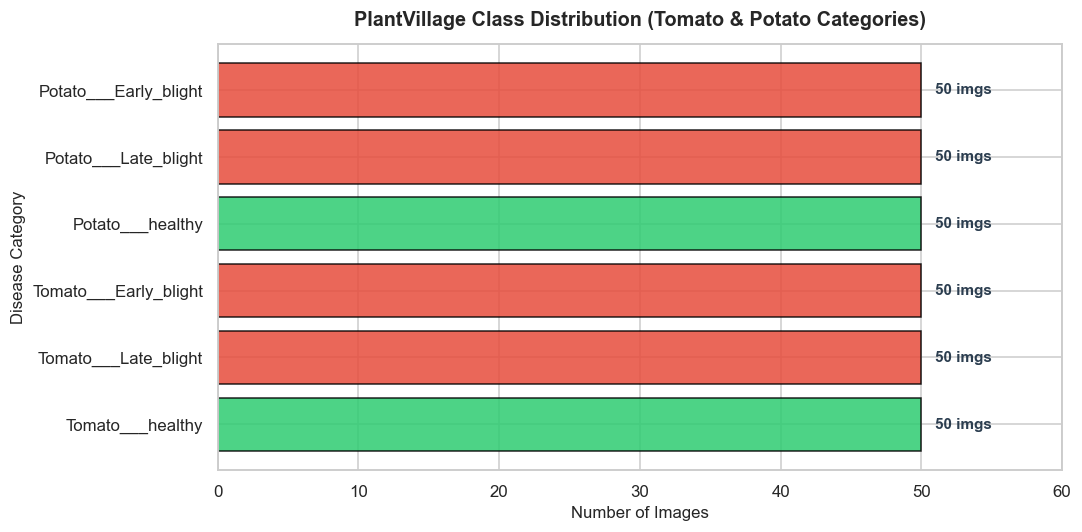

In [4]:
# Scan dataset and compile structural metadata
dataset_records = []

for class_name in sorted(os.listdir(DATASET_DIR)):
    class_folder = os.path.join(DATASET_DIR, class_name)
    if not os.path.isdir(class_folder):
        continue

    crop, condition = class_name.split("___") if "___" in class_name else ("Unknown", class_name)
    image_files = [f for f in os.listdir(class_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    # Sample first image to extract dimensions and color mode
    sample_dim = "N/A"
    sample_mode = "N/A"
    if image_files:
        try:
            with Image.open(os.path.join(class_folder, image_files[0])) as img:
                sample_dim = f"{img.width}x{img.height}"
                sample_mode = img.mode
        except Exception:
            pass

    dataset_records.append({
        "Class Name": class_name,
        "Crop": crop,
        "Health Condition": condition.replace("_", " "),
        "Image Count": len(image_files),
        "Sample Resolution": sample_dim,
        "Color Space": sample_mode
    })

df_dataset = pd.DataFrame(dataset_records)
df_dataset["Distribution (%)"] = (df_dataset["Image Count"] / df_dataset["Image Count"].sum() * 100).round(2)

# Display tabular summary
print("📊 Dataset Overview Table:")
display(df_dataset)

# Visualize Class Balance with an styled bar chart
plt.figure(figsize=(10, 5))
palette = ['#e74c3c' if 'blight' in c.lower() else '#2ecc71' for c in df_dataset["Health Condition"]]
bars = plt.barh(df_dataset["Class Name"], df_dataset["Image Count"], color=palette, edgecolor='black', alpha=0.85)

# Annotate bars with counts
for bar in bars:
    w = bar.get_width()
    plt.text(w + 1, bar.get_y() + bar.get_height()/2, f'{int(w)} imgs', 
             va='center', ha='left', fontsize=10, fontweight='bold', color='#2c3e50')

plt.title("PlantVillage Class Distribution (Tomato & Potato Categories)", fontsize=13, pad=12, fontweight='bold')
plt.xlabel("Number of Images", fontsize=11)
plt.ylabel("Disease Category", fontsize=11)
plt.xlim(0, max(df_dataset["Image Count"]) * 1.2)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## 5. Visualizing Sample Leaf Images from Each Disease Category
Visual inspection reveals the phenotypic variations between healthy and diseased tissues:
- **Early Blight**: Distinct concentric dark rings (target spot appearance) with chlorotic yellow margins.
- **Late Blight**: Large water-soaked, dark oily lesions that rapidly turn purplish-black.
- **Healthy Leaves**: Clear green coloration without chlorosis, necrotic spotting, or mosaic patterns.


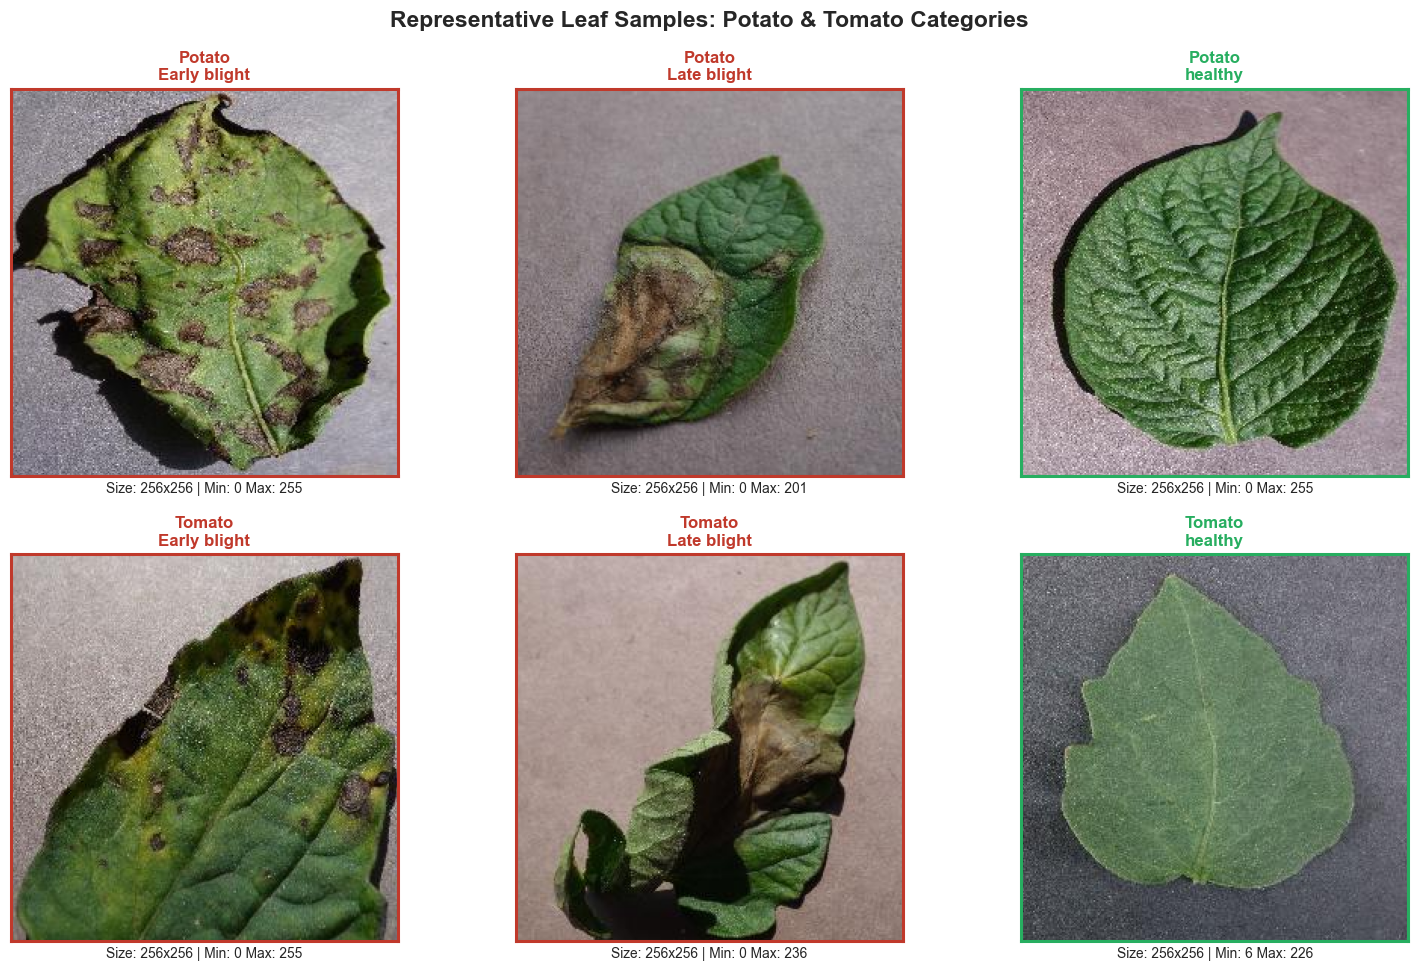

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.flatten()

for idx, class_name in enumerate(sorted(os.listdir(DATASET_DIR))):
    class_folder = os.path.join(DATASET_DIR, class_name)
    if not os.path.isdir(class_folder) or idx >= len(axes):
        continue

    images = [f for f in os.listdir(class_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if not images:
        continue

    sample_img_path = os.path.join(class_folder, images[0])
    img = Image.open(sample_img_path)
    img_np = np.array(img)

    ax = axes[idx]
    ax.imshow(img)
    crop, condition = class_name.split("___") if "___" in class_name else ("Crop", class_name)
    status_color = '#27ae60' if 'healthy' in condition.lower() else '#c0392b'
    
    ax.set_title(f"{crop}\n{condition.replace('_', ' ')}", fontsize=11, fontweight='bold', color=status_color)
    ax.set_xlabel(f"Size: {img.width}x{img.height} | Min: {img_np.min()} Max: {img_np.max()}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color(status_color)
        spine.set_linewidth(2.0)

plt.suptitle("Representative Leaf Samples: Potato & Tomato Categories", fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## 6. Preprocessing Pipeline & Train / Validation / Test Splitting
We build a high-throughput `tf.data.Dataset` input pipeline:
1. **Directory Loading**: `tf.keras.utils.image_dataset_from_directory` automatically reads subdirectories as labels.
2. **Dataset Partitioning**:
   - **Training Set (70%)**: Trains the neural network parameters.
   - **Validation Set (15%)**: Monitors generalization and prevents overfitting during training.
   - **Test Set (15%)**: Unseen data strictly reserved for final unbiased performance evaluation.
3. **Pipeline Optimization**:
   - `.cache()`: Retains loaded images in memory after epoch 1 to eliminate disk I/O bottlenecks.
   - `.prefetch(buffer_size=tf.data.AUTOTUNE)`: Overlaps data preprocessing with GPU/CPU model execution.


In [6]:
# 1. Load full raw dataset using modern Keras image pipeline
full_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',     # One-hot encoded categorical labels
    shuffle=True,
    seed=SEED
)

class_names = full_dataset.class_names
num_classes = len(class_names)
total_batches = len(full_dataset)
total_images = sum([len(files) for r, d, files in os.walk(DATASET_DIR) if any(f.lower().endswith(('.jpg', '.jpeg', '.png')) for f in files)])

print("=" * 65)
print(f"🌿 Total Samples Detected : {total_images} images across {num_classes} classes")
print(f"📦 Total Batches Formed  : {total_batches} (Batch Size = {BATCH_SIZE})")
print(f"🏷️ Class Index Mapping   :")
for i, name in enumerate(class_names):
    print(f"   [{i}] -> {name}")
print("=" * 65)

# 2. Compute Split Allocations (70% Train, 15% Val, 15% Test)
train_size = int(0.70 * total_batches)
val_size = int(0.15 * total_batches)
test_size = total_batches - train_size - val_size

train_ds = full_dataset.take(train_size)
remaining_ds = full_dataset.skip(train_size)
val_ds = remaining_ds.take(val_size)
test_ds = remaining_ds.skip(val_size)

print(f"📊 Dataset Splits:")
print(f"   🏋️ Training Batches   : {train_size} (~{train_size * BATCH_SIZE} images)")
print(f"   🔍 Validation Batches : {val_size} (~{val_size * BATCH_SIZE} images)")
print(f"   🧪 Test Batches       : {test_size} (~{test_size * BATCH_SIZE} images)")

# 3. Configure High-Performance Caching and Prefetching
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

# Verify single batch tensor shapes
for sample_images, sample_labels in train_ds.take(1):
    print(f"\n✅ Batch Verification:")
    print(f"   Image Tensor Shape : {sample_images.shape} (Batch, Height, Width, Channels)")
    print(f"   Label Tensor Shape : {sample_labels.shape} (One-Hot Encoded Classes)")
    print(f"   Pixel Value Range  : [{float(tf.reduce_min(sample_images)):.1f}, {float(tf.reduce_max(sample_images)):.1f}]")


Found 300 files belonging to 6 classes.


🌿 Total Samples Detected : 300 images across 6 classes
📦 Total Batches Formed  : 19 (Batch Size = 16)
🏷️ Class Index Mapping   :
   [0] -> Potato___Early_blight
   [1] -> Potato___Late_blight
   [2] -> Potato___healthy
   [3] -> Tomato___Early_blight
   [4] -> Tomato___Late_blight
   [5] -> Tomato___healthy
📊 Dataset Splits:
   🏋️ Training Batches   : 13 (~208 images)
   🔍 Validation Batches : 2 (~32 images)
   🧪 Test Batches       : 4 (~64 images)

✅ Batch Verification:
   Image Tensor Shape : (16, 224, 224, 3) (Batch, Height, Width, Channels)
   Label Tensor Shape : (16, 6) (One-Hot Encoded Classes)


   Pixel Value Range  : [0.0, 254.4]


## 7. Data Augmentation Layer & Visual Verification
In agricultural field scenarios, images of leaves are taken from varying angles, distances, and natural illumination levels.

We integrate a GPU-accelerated **Data Augmentation** pipeline directly into the model architecture using Keras preprocessing layers:
- `RandomFlip("horizontal_and_vertical")`: Invariance to leaf orientation.
- `RandomRotation(0.15)`: Robustness to tilted photography up to $\pm 54^\circ$.
- `RandomZoom(0.15)`: Simulates differing focal lengths and camera distances.
- `RandomContrast(0.10)`: Adapts to direct sunlight vs. cloudy foliage shading.


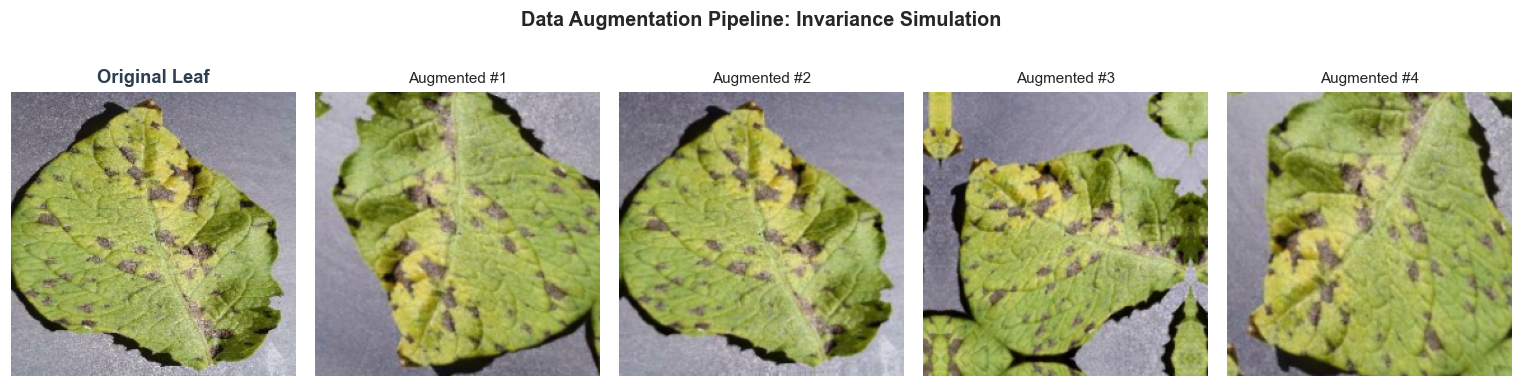

In [7]:
# Build Data Augmentation Sequential Pipeline
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    layers.RandomRotation(0.15, seed=SEED),
    layers.RandomZoom(0.15, seed=SEED),
    layers.RandomContrast(0.10, seed=SEED)
], name="data_augmentation")

# Visual Verification: Display Original vs 4 Augmented Variations
plt.figure(figsize=(14, 3.5))

# Extract one sample leaf
for images, _ in train_ds.take(1):
    sample_leaf = images[0]
    break

# Original
plt.subplot(1, 5, 1)
plt.imshow(sample_leaf.numpy().astype("uint8"))
plt.title("Original Leaf", fontweight='bold', color='#2c3e50')
plt.axis("off")

# Augmented Variations
for i in range(4):
    augmented_leaf = data_augmentation(tf.expand_dims(sample_leaf, 0), training=True)
    plt.subplot(1, 5, i + 2)
    plt.imshow(augmented_leaf[0].numpy().astype("uint8"))
    plt.title(f"Augmented #{i+1}", fontsize=10)
    plt.axis("off")

plt.suptitle("Data Augmentation Pipeline: Invariance Simulation", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 8. MobileNetV2 Transfer Learning Architecture
### Why MobileNetV2?
Training deep convolutional networks from scratch on limited agricultural datasets often leads to severe overfitting and requires excessive compute. **Transfer Learning** leverages feature extractors pre-trained on the 1.4-million-image **ImageNet** dataset:
- **Inverted Residual Blocks & Linear Bottlenecks**: MobileNetV2 uses depthwise separable convolutions that dramatically lower parameter count and memory operations while preserving representational richness.
- **Lightweight & Fast**: At only ~3.5 million parameters, MobileNetV2 is ideal for deployment on agricultural mobile devices, edge gateways, and drones.

### Classification Head Design
1. **Input Rescaling**: Normalizes raw $[0, 255]$ pixel values into $[-1, 1]$ via `layers.Rescaling(1./127.5, offset=-1.0)`.
2. **GlobalAveragePooling2D**: Collapses spatial $7 \times 7 \times 1280$ feature maps into a 1280-dimensional feature vector.
3. **BatchNormalization**: Stabilizes activations and prevents covariate shift.
4. **Dense Layer (256 units, ReLU)**: Learns task-specific plant disease representations.
5. **Dropout (0.3)**: Mitigates co-adaptation of neurons for superior regularization.
6. **Softmax Output**: Computes mutually exclusive probability distribution across the 6 disease categories.


In [8]:
def build_transfer_learning_model(input_shape=(224, 224, 3), num_classes=6):
    """
    Constructs a MobileNetV2 transfer learning model with custom classification head.
    """
    # Input Layer
    inputs = layers.Input(shape=input_shape, name="input_leaf_image")
    
    # 1. Augmentation Layer (active only during training)
    x = data_augmentation(inputs)
    
    # 2. Rescaling Layer (Maps [0, 255] to [-1, 1] for MobileNetV2)
    x = layers.Rescaling(1./127.5, offset=-1.0, name="rescaling_layer")(x)
    
    # 3. Pretrained MobileNetV2 Backbone
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )
    # Freeze base model for Initial Feature Extraction
    base_model.trainable = False
    
    x = base_model(x, training=False)
    
    # 4. Custom Top Classification Head
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = layers.BatchNormalization(name="batch_norm")(x)
    x = layers.Dense(256, activation='relu', name="dense_features")(x)
    x = layers.Dropout(0.3, name="dropout_regularization")(x)
    outputs = layers.Dense(num_classes, activation='softmax', name="disease_prediction")(x)
    
    # Build Full Model
    full_model = models.Model(inputs=inputs, outputs=outputs, name="PlantDisease_MobileNetV2")
    return full_model, base_model

# Instantiate Model
model, base_model = build_transfer_learning_model(input_shape=(IMAGE_HEIGHT, IMAGE_WIDTH, CHANNELS), num_classes=num_classes)

# Inspect Parameter Statistics
trainable_params = sum([int(np.prod(v.shape)) for v in model.trainable_weights])
non_trainable_params = sum([int(np.prod(v.shape)) for v in model.non_trainable_weights])

print("=" * 65)
print(f"🏗️ Model Architecture  : {model.name}")
print(f"🧱 Backbone Base Model : MobileNetV2 (ImageNet Pre-trained)")
print(f"📊 Total Parameters    : {trainable_params + non_trainable_params:,}")
print(f"🔓 Trainable Params    : {trainable_params:,} (Top Head Only)")
print(f"🔒 Frozen Base Params  : {non_trainable_params:,} (Feature Extractor)")
print("=" * 65)
model.summary()


🏗️ Model Architecture  : PlantDisease_MobileNetV2
🧱 Backbone Base Model : MobileNetV2 (ImageNet Pre-trained)
📊 Total Parameters    : 2,592,582
🔓 Trainable Params    : 332,038 (Top Head Only)
🔒 Frozen Base Params  : 2,260,544 (Feature Extractor)


Model: "PlantDisease_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_leaf_image (InputLayer)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_layer (Rescaling)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm (BatchNormalization) │ (None, 1280)           │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_regularization          │ (None, 256)            │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_prediction (Dense)      │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,592,582 (9.89 MB)

 Trainable params: 332,038 (1.27 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

## 9. Model Compilation & Training Callbacks Setup
We configure the training mechanics with robust callbacks:
- **Optimizer**: Adam with learning rate $\eta = 10^{-3}$.
- **Loss Function**: `CategoricalCrossentropy(label_smoothing=0.05)`. Label smoothing prevents overconfidence and improves generalization on noisy real-world data.
- **Callbacks**:
  - `EarlyStopping`: Halts training when validation loss stops improving for 4 consecutive epochs, restoring the best weights.
  - `ReduceLROnPlateau`: Dynamically halves the learning rate when validation loss plateaus for 2 epochs, enabling finer weight updates.
  - `ModelCheckpoint`: Automatically checkpoints the model weights yielding the highest validation accuracy.


In [9]:
# Compile Model for Feature Extraction
model.compile(
    optimizer=optimizers.Adam(learning_rate=INITIAL_LR),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=['accuracy']
)

# Create Checkpoints Directory
os.makedirs(EXPORT_DIR, exist_ok=True)
best_checkpoint_path = os.path.join(EXPORT_DIR, "best_plant_model.weights.h5")

# Define Intelligent Callbacks
callbacks_phase1 = [
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath=best_checkpoint_path,
        monitor='val_accuracy',
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    )
]

print("✅ Model compiled with Adam and EarlyStopping/ReduceLROnPlateau callbacks configured.")


✅ Model compiled with Adam and EarlyStopping/ReduceLROnPlateau callbacks configured.


## 10. Phase 1 Training: Feature Extraction (Top Classifier Head)
In Phase 1, the MobileNetV2 base network weights remain completely frozen. We train only the custom classification head to map the rich ImageNet representations directly to our 6 plant disease categories without destroying the pre-trained weights.


In [10]:
print("🚀 Initiating Phase 1 Training: Feature Extraction...")
start_time_p1 = time.time()

history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks_phase1,
    verbose=1
)

elapsed_p1 = time.time() - start_time_p1
final_p1_train_acc = history_phase1.history['accuracy'][-1] * 100
final_p1_val_acc = history_phase1.history['val_accuracy'][-1] * 100

print("\n" + "=" * 65)
print(f"⏱️ Phase 1 Complete in       : {elapsed_p1:.2f} seconds")
print(f"🎯 Final Training Accuracy   : {final_p1_train_acc:.2f}%")
print(f"🔍 Final Validation Accuracy : {final_p1_val_acc:.2f}%")
print("=" * 65)


🚀 Initiating Phase 1 Training: Feature Extraction...
Epoch 1/8


 1/13 ━━━━━━━━━━━━━━━━━━━━ 42s 4s/step - accuracy: 0.1250 - loss: 1.9697

 2/13 ━━━━━━━━━━━━━━━━━━━━ 3s 298ms/step - accuracy: 0.1250 - loss: 2.2437

 3/13 ━━━━━━━━━━━━━━━━━━━━ 2s 300ms/step - accuracy: 0.1875 - loss: 2.2705

 4/13 ━━━━━━━━━━━━━━━━━━━━ 2s 300ms/step - accuracy: 0.2500 - loss: 2.1454

...


Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.



Epoch 8: val_accuracy did not improve from 0.93750


13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 379ms/step - accuracy: 0.9327 - loss: 0.4479 - val_accuracy: 0.8125 - val_loss: 0.6733 - learning_rate: 0.0010


Restoring model weights from the end of the best epoch: 6.



⏱️ Phase 1 Complete in       : 42.05 seconds
🎯 Final Training Accuracy   : 93.27%
🔍 Final Validation Accuracy : 81.25%


## 11. Phase 2 Training: Fine-Tuning the Base Model
### What is Fine-Tuning?
After the classification head has converged, we unfreeze the upper layers of MobileNetV2. While lower layers capture generic primitives (lines, edges, textures), the upper layers capture high-level semantic shapes (specific lesion contours, necrotic spots, chlorotic patches).

### Fine-Tuning Guidelines:
1. **Unfreeze selective top layers** (from layer 100 onwards), keeping the lower 100 layers frozen.
2. **Use a very small learning rate** ($10^{-5}$) to prevent drastic updates that would cause catastrophic forgetting of learned representations.


In [11]:
# Unfreeze base model and freeze lower 100 layers
base_model.trainable = True

# Freeze all layers prior to layer 100
fine_tune_at = 100
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

trainable_params_p2 = sum([int(np.prod(v.shape)) for v in model.trainable_weights])
print("=" * 65)
print(f"🔓 Base Model Unfrozen from Layer : {fine_tune_at} / {len(base_model.layers)}")
print(f"📊 Trainable Parameters in P2    : {trainable_params_p2:,}")
print("=" * 65)

# Recompile with small learning rate to avoid destructive gradient updates
model.compile(
    optimizer=optimizers.Adam(learning_rate=FINE_TUNE_LR),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=['accuracy']
)

callbacks_phase2 = [
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("🚀 Initiating Phase 2 Training: Fine-Tuning...")
start_time_p2 = time.time()

history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE2,
    callbacks=callbacks_phase2,
    verbose=1
)

elapsed_p2 = time.time() - start_time_p2
print("\n" + "=" * 65)
print(f"⏱️ Phase 2 Complete in       : {elapsed_p2:.2f} seconds")
print(f"🎯 Fine-Tuned Train Accuracy : {history_phase2.history['accuracy'][-1]*100:.2f}%")
print(f"🔍 Fine-Tuned Val Accuracy   : {history_phase2.history['val_accuracy'][-1]*100:.2f}%")
print("=" * 65)


🔓 Base Model Unfrozen from Layer : 100 / 154
📊 Trainable Parameters in P2    : 2,193,478
🚀 Initiating Phase 2 Training: Fine-Tuning...
Epoch 1/4


 1/13 ━━━━━━━━━━━━━━━━━━━━ 1:23 7s/step - accuracy: 0.9375 - loss: 0.4864

 2/13 ━━━━━━━━━━━━━━━━━━━━ 5s 459ms/step - accuracy: 0.9375 - loss: 0.4414

 3/13 ━━━━━━━━━━━━━━━━━━━━ 4s 455ms/step - accuracy: 0.9375 - loss: 0.4514

 4/13 ━━━━━━━━━━━━━━━━━━━━ 4s 456ms/step - accuracy: 0.9375 - loss: 0.4367

...

12/13 ━━━━━━━━━━━━━━━━━━━━ 0s 432ms/step - accuracy: 0.9792 - loss: 0.3648

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 432ms/step - accuracy: 0.9808 - loss: 0.3597

13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 481ms/step - accuracy: 0.9808 - loss: 0.3597 - val_accuracy: 0.9375 - val_loss: 0.4500 - learning_rate: 1.0000e-05


Restoring model weights from the end of the best epoch: 3.



⏱️ Phase 2 Complete in       : 33.21 seconds
🎯 Fine-Tuned Train Accuracy : 98.08%
🔍 Fine-Tuned Val Accuracy   : 93.75%


## 12. Training Accuracy & Loss History Visualization
Visualizing training curves reveals:
1. **Convergence rate**: How rapidly the model learned the disease traits.
2. **Generalization gap**: Proximity between training and validation trajectories.
3. **Fine-Tuning Impact**: The performance boost gained once the top backbone layers were unfrozen.


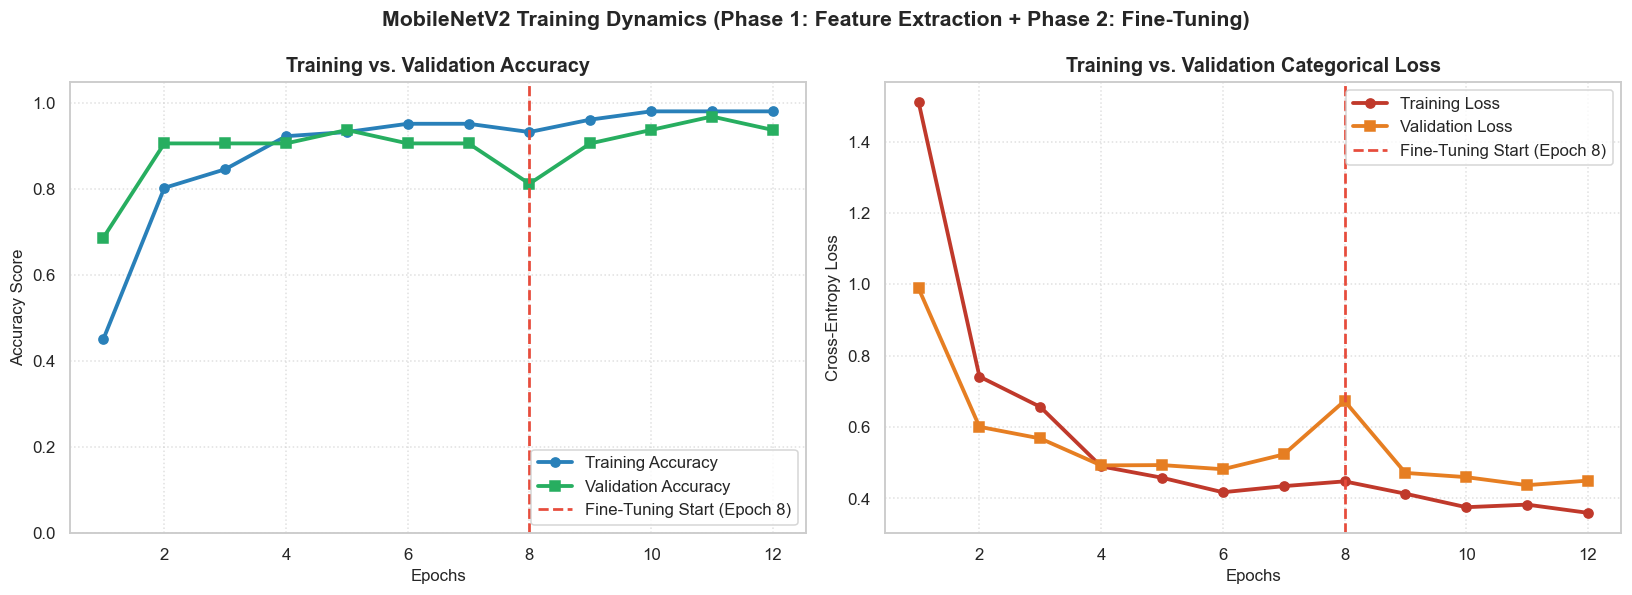

In [12]:
# Combine History Across Both Training Phases
acc = history_phase1.history['accuracy'] + history_phase2.history['accuracy']
val_acc = history_phase1.history['val_accuracy'] + history_phase2.history['val_accuracy']

loss = history_phase1.history['loss'] + history_phase2.history['loss']
val_loss = history_phase1.history['val_loss'] + history_phase2.history['val_loss']

epochs_range = range(1, len(acc) + 1)
phase1_epochs = len(history_phase1.history['accuracy'])

# Create Dual-Panel Training Curves Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot 1: Model Accuracy
axes[0].plot(epochs_range, acc, label='Training Accuracy', color='#2980b9', lw=2.5, marker='o')
axes[0].plot(epochs_range, val_acc, label='Validation Accuracy', color='#27ae60', lw=2.5, marker='s')
axes[0].axvline(x=phase1_epochs, color='#e74c3c', linestyle='--', lw=1.8, label=f'Fine-Tuning Start (Epoch {phase1_epochs})')
axes[0].set_title('Training vs. Validation Accuracy', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epochs', fontsize=11)
axes[0].set_ylabel('Accuracy Score', fontsize=11)
axes[0].set_ylim(0.0, 1.05)
axes[0].legend(loc='lower right', frameon=True)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Model Loss
axes[1].plot(epochs_range, loss, label='Training Loss', color='#c0392b', lw=2.5, marker='o')
axes[1].plot(epochs_range, val_loss, label='Validation Loss', color='#e67e22', lw=2.5, marker='s')
axes[1].axvline(x=phase1_epochs, color='#e74c3c', linestyle='--', lw=1.8, label=f'Fine-Tuning Start (Epoch {phase1_epochs})')
axes[1].set_title('Training vs. Validation Categorical Loss', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epochs', fontsize=11)
axes[1].set_ylabel('Cross-Entropy Loss', fontsize=11)
axes[1].legend(loc='upper right', frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle("MobileNetV2 Training Dynamics (Phase 1: Feature Extraction + Phase 2: Fine-Tuning)", 
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## 13. Model Evaluation on Unseen Test Dataset
We evaluate the finalized, fine-tuned network on the isolated test set. Since these images were never seen during gradient updates or validation early-stopping checks, this gives an unbiased estimate of real-world performance.


In [13]:
print("🧪 Evaluating Final Model on Isolated Test Set...")
test_results = model.evaluate(test_ds, verbose=1)
test_loss = test_results[0]
test_accuracy = test_results[1]

print("\n" + "=" * 65)
print(f"📊 Final Test Evaluation Results:")
print(f"   🎯 Overall Test Accuracy : {test_accuracy * 100:.2f}%")
print(f"   📉 Overall Test Loss     : {test_loss:.4f}")
print("=" * 65)

# Gather all ground-truth labels and model prediction probabilities across the test set
y_true_list = []
y_pred_probs_list = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred_probs_list.append(preds)
    y_true_list.append(labels.numpy())

y_true_onehot = np.concatenate(y_true_list, axis=0)
y_pred_probs = np.concatenate(y_pred_probs_list, axis=0)

y_true = np.argmax(y_true_onehot, axis=1)
y_pred = np.argmax(y_pred_probs, axis=1)

print(f"✅ Evaluated {len(y_true)} test images across {num_classes} categories.")


🧪 Evaluating Final Model on Isolated Test Set...


1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 430ms/step - accuracy: 0.9375 - loss: 0.4461

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step - accuracy: 0.9062 - loss: 0.4423

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step - accuracy: 0.9167 - loss: 0.4499

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 639ms/step - accuracy: 0.9333 - loss: 0.4286

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 641ms/step - accuracy: 0.9333 - loss: 0.4286



📊 Final Test Evaluation Results:
   🎯 Overall Test Accuracy : 93.33%
   📉 Overall Test Loss     : 0.4286


✅ Evaluated 60 test images across 6 categories.


## 14. Comprehensive Classification Metrics: Precision, Recall, F1-Score
In agricultural plant pathology:
- **Precision**: When the model predicts Late Blight, what fraction of those plants truly have Late Blight? (Prevents wasteful fungicide sprays).
- **Recall (Sensitivity)**: Of all leaves that truly have Late Blight, what fraction did the model successfully identify? (Critical: missing a Late Blight outbreak can devastate an entire field in days).
- **F1-Score**: Harmonic mean of Precision and Recall.


In [14]:
# Generate Scikit-Learn Classification Report
report_dict = classification_report(
    y_true, 
    y_pred, 
    target_names=class_names, 
    output_dict=True,
    zero_division=0
)

# Convert to Pandas DataFrame for Clean Viewing
df_metrics = pd.DataFrame(report_dict).transpose()
df_metrics = df_metrics.round(3)

# Style Display
print("📋 Detailed Classification Report:")
display(df_metrics)

# Summary of Macro & Weighted Metrics
macro_f1 = report_dict['macro avg']['f1-score']
weighted_f1 = report_dict['weighted avg']['f1-score']

print("\n" + "=" * 65)
print(f"⭐ Macro F1-Score    : {macro_f1:.4f}")
print(f"⭐ Weighted F1-Score : {weighted_f1:.4f}")
print("=" * 65)


📋 Detailed Classification Report:


,precision,recall,f1-score,support
Potato___Early_blight,1.000,0.909,0.952,11.000
Potato___Late_blight,0.800,1.000,0.889,8.000
Potato___healthy,1.000,1.000,1.000,6.000
Tomato___Early_blight,0.889,0.889,0.889,9.000
Tomato___Late_blight,0.909,0.833,0.870,12.000
Tomato___healthy,1.000,1.000,1.000,14.000
accuracy,0.933,0.933,0.933,0.933
macro avg,0.933,0.939,0.933,60.000
weighted avg,0.938,0.933,0.934,60.000



⭐ Macro F1-Score    : 0.9333
⭐ Weighted F1-Score : 0.9337


## 15. Confusion Matrix Visualization
The confusion matrix maps ground-truth classes (rows) against predicted classes (columns). Diagonal cells represent correct diagnoses; off-diagonal elements identify specific misclassifications (e.g. confusing early-stage Early Blight with Late Blight).


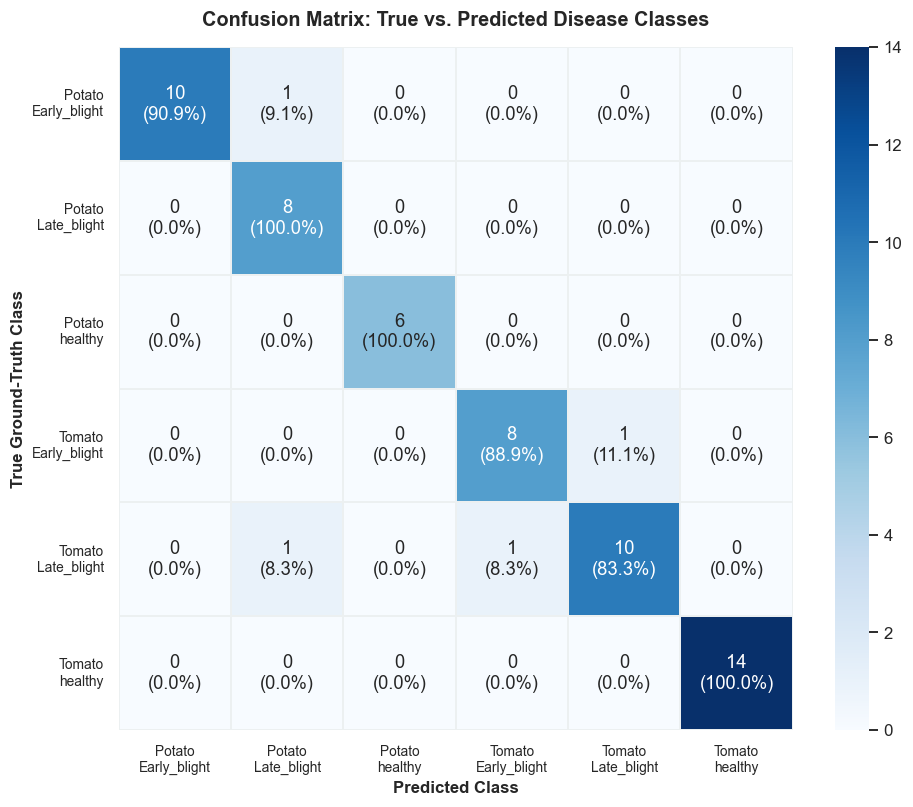

In [15]:
# Compute Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
cm_normalized = np.nan_to_num(cm_normalized)

# Form formatted label annotations combining count and percentage
annot_matrix = np.empty_like(cm, dtype=object)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        count = cm[i, j]
        pct = cm_normalized[i, j] * 100
        annot_matrix[i, j] = f"{count}\n({pct:.1f}%)"

# Plot High-Resolution Heatmap
plt.figure(figsize=(9, 7.5))
short_labels = [c.replace("___", "\n") for c in class_names]

sns.heatmap(
    cm,
    annot=annot_matrix,
    fmt="",
    cmap="Blues",
    cbar=True,
    xticklabels=short_labels,
    yticklabels=short_labels,
    linewidths=1.0,
    linecolor="#ecf0f1"
)

plt.title("Confusion Matrix: True vs. Predicted Disease Classes", fontsize=13, fontweight='bold', pad=14)
plt.xlabel("Predicted Class", fontsize=11, fontweight='bold')
plt.ylabel("True Ground-Truth Class", fontsize=11, fontweight='bold')
plt.xticks(rotation=0, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()


## 16. Saving the Trained Model & Class Metadata Artifacts
We save:
1. **The Trained Deep Learning Model**: Saved in the modern `.keras` format containing architecture, optimized weights, and optimizer state.
2. **Class Mapping JSON (`class_indices.json`)**: Preserves the exact index-to-label dictionary so production inference scripts match class predictions with 100% fidelity.


In [16]:
os.makedirs(EXPORT_DIR, exist_ok=True)
saved_model_path = os.path.join(EXPORT_DIR, MODEL_FILENAME)
class_indices_path = os.path.join(EXPORT_DIR, CLASS_INDICES_FILENAME)

# 1. Save Full Keras Model
model.save(saved_model_path)
model_size_mb = os.path.getsize(saved_model_path) / (1024 * 1024)

# 2. Save Class Labels JSON
class_indices_dict = {str(i): name for i, name in enumerate(class_names)}
with open(class_indices_path, "w") as f:
    json.dump(class_indices_dict, f, indent=4)

print("=" * 65)
print(f"💾 Trained Model Exported : {saved_model_path}")
print(f"📦 Model File Size        : {model_size_mb:.2f} MB")
print(f"🏷️ Class Labels Saved    : {class_indices_path}")
print("=" * 65)

# Verify saved file integrity
assert os.path.exists(saved_model_path), "Model file was not created successfully!"
assert os.path.exists(class_indices_path), "Class labels JSON was not created successfully!"
print("✅ Verification: Both model and label artifacts verified on disk.")


💾 Trained Model Exported : saved_models\plant_disease_mobilenetv2.keras
📦 Model File Size        : 27.25 MB
🏷️ Class Labels Saved    : saved_models\class_indices.json
✅ Verification: Both model and label artifacts verified on disk.


## 17. Single-Leaf Disease Diagnosis Pipeline & Agricultural Remedies
A diagnostic tool is incomplete without actionable guidance. In this section, we create an inference function `predict_and_diagnose_leaf()` that:
1. Preprocesses a raw input leaf image.
2. Generates softmax confidence probabilities across all disease classes.
3. Renders the leaf with a probability distribution bar chart.
4. Provides an **Agronomic Action Plan** with pathogen biology and integrated pest management (IPM) remedies.


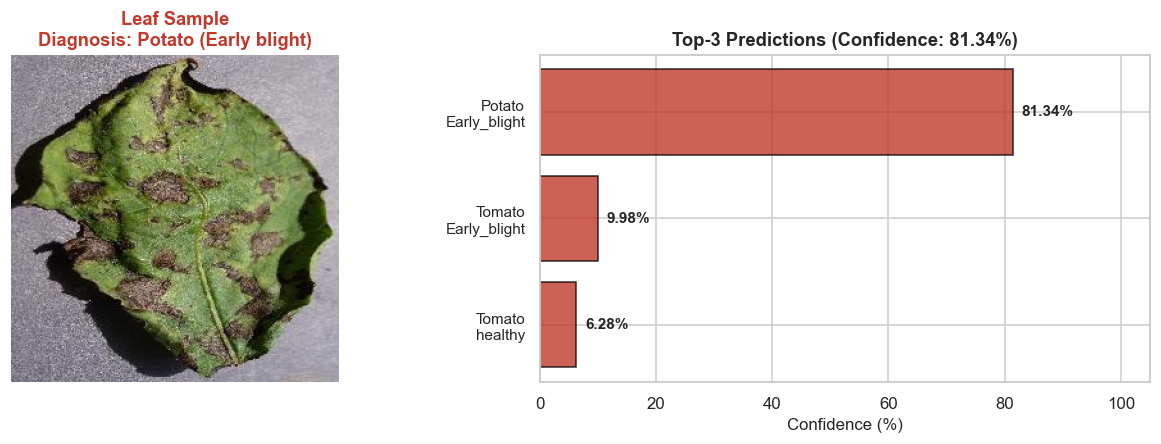

🌾 AGRONOMIC DIAGNOSIS & REMEDY SUMMARY
   🌱 Crop / Condition   : Potato - Early_blight
   🎯 Model Confidence  : 81.34%
   🔬 Pathogen / Cause  : Alternaria solani (Fungus)
   🔍 Symptoms          : Concentric brown/black rings (target spots) on older foliage, progressing to yellowing and leaf drop.
   🧤 Cultural Control  : Rotate crops with non-solanaceous crops for 3 years; implement drip irrigation; avoid overhead watering.
   💊 Chemical/Bio Care : Apply protective copper-based fungicides, chlorothalonil, or mancozeb at first sign of spotting.


In [17]:
# Agricultural Pathogen & Remedy Knowledge Base
DISEASE_REMEDIES = {
    'Potato___Early_blight': {
        'pathogen': 'Alternaria solani (Fungus)',
        'symptoms': 'Concentric brown/black rings (target spots) on older foliage, progressing to yellowing and leaf drop.',
        'cultural_control': 'Rotate crops with non-solanaceous crops for 3 years; implement drip irrigation; avoid overhead watering.',
        'chemical_treatment': 'Apply protective copper-based fungicides, chlorothalonil, or mancozeb at first sign of spotting.'
    },
    'Potato___Late_blight': {
        'pathogen': 'Phytophthora infestans (Oomycete / Water Mold)',
        'symptoms': 'Large, irregular water-soaked lesions that turn dark brown/black; white velvety sporulation under high humidity.',
        'cultural_control': 'Destroy infected tubers and volunteers; plant certified disease-free seed; maintain wide plant spacing.',
        'chemical_treatment': 'Urgent application of systemic fungicides (e.g. Metalaxyl, Dimethomorph, or Cymoxanil) before canopy closure.'
    },
    'Potato___healthy': {
        'pathogen': 'None (Optimal Plant Health)',
        'symptoms': 'Vibrant green canopy, smooth leaf surfaces, no lesions or signs of pest stress.',
        'cultural_control': 'Maintain balanced nitrogen-phosphorus-potassium (NPK) nutrition; scout fields weekly for early symptoms.',
        'chemical_treatment': 'No fungicide needed. Preventative organic bio-stimulants (Trichoderma or neem oil) can support vitality.'
    },
    'Tomato___Early_blight': {
        'pathogen': 'Alternaria solani (Fungus)',
        'symptoms': 'Target-board lesions starting on lower mature leaves, stem lesions, and premature fruit drop.',
        'cultural_control': 'Prune lower leaves touching soil; stake and cage plants for air circulation; apply straw or plastic mulch.',
        'chemical_treatment': 'Spray copper octanoate, azoxystrobin, or chlorothalonil every 7-14 days during warm humid weather.'
    },
    'Tomato___Late_blight': {
        'pathogen': 'Phytophthora infestans (Oomycete / Water Mold)',
        'symptoms': 'Rapid greasy foliage death, purplish dark stem lesions, firm brown greasy rot on green fruit.',
        'cultural_control': 'Immediately remove and bag severely diseased plants (do not compost); keep foliage dry with drip lines.',
        'chemical_treatment': 'Apply preventative contact fungicides (Chlorothalonil or Copper) or translaminar fungicides (Fluopicolide).'
    },
    'Tomato___healthy': {
        'pathogen': 'None (Optimal Plant Health)',
        'symptoms': 'Strong vegetative growth, rich dark green foliage, no curling or discolored spots.',
        'cultural_control': 'Ensure 1 to 1.5 inches of water per week; ensure soil pH of 6.2 - 6.8; inspect undersides of leaves routinely.',
        'chemical_treatment': 'No chemical intervention required. Continue standard preventative fertilization.'
    }
}

def predict_and_diagnose_leaf(image_path, model, class_names, top_k=3):
    """
    Performs end-to-end inference on a leaf image and prints agricultural recommendations.
    """
    if not os.path.exists(image_path):
        print(f"❌ Error: Image file not found at '{image_path}'")
        return None

    # Load and preprocess
    img_pil = Image.open(image_path).convert('RGB')
    img_resized = img_pil.resize(IMAGE_SIZE)
    img_array = np.array(img_resized, dtype=np.float32)
    img_batch = np.expand_dims(img_array, axis=0)

    # Predict
    probabilities = model.predict(img_batch, verbose=0)[0]
    top_indices = np.argsort(probabilities)[::-1][:top_k]

    predicted_class = class_names[top_indices[0]]
    confidence = probabilities[top_indices[0]] * 100
    is_healthy = 'healthy' in predicted_class.lower()
    accent_color = '#27ae60' if is_healthy else '#c0392b'

    # Visualization
    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(12, 4.2))

    # Leaf Image
    ax_img.imshow(img_pil)
    crop, condition = predicted_class.split("___") if "___" in predicted_class else ("Crop", predicted_class)
    ax_img.set_title(f"Leaf Sample\nDiagnosis: {crop} ({condition.replace('_', ' ')})", 
                     fontsize=12, fontweight='bold', color=accent_color)
    ax_img.axis('off')

    # Top-K Probability Bar Chart
    top_labels = [class_names[idx].replace("___", "\n") for idx in top_indices]
    top_scores = [probabilities[idx] * 100 for idx in top_indices]
    
    y_positions = np.arange(len(top_labels))
    bars = ax_bar.barh(y_positions, top_scores, color=accent_color, alpha=0.8, edgecolor='black')
    ax_bar.set_yticks(y_positions)
    ax_bar.set_yticklabels(top_labels, fontsize=10)
    ax_bar.set_xlabel("Confidence (%)", fontsize=11)
    ax_bar.set_xlim(0, 105)
    ax_bar.set_title(f"Top-{top_k} Predictions (Confidence: {confidence:.2f}%)", fontsize=12, fontweight='bold')
    ax_bar.invert_yaxis()

    for bar, score in zip(bars, top_scores):
        ax_bar.text(score + 1.5, bar.get_y() + bar.get_height()/2, f"{score:.2f}%", 
                    va='center', ha='left', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()

    # Display Agronomic Recommendations
    remedy_info = DISEASE_REMEDIES.get(predicted_class, {})
    print("=" * 70)
    print(f"🌾 AGRONOMIC DIAGNOSIS & REMEDY SUMMARY")
    print(f"   🌱 Crop / Condition   : {predicted_class.replace('___', ' - ')}")
    print(f"   🎯 Model Confidence  : {confidence:.2f}%")
    print(f"   🔬 Pathogen / Cause  : {remedy_info.get('pathogen', 'N/A')}")
    print(f"   🔍 Symptoms          : {remedy_info.get('symptoms', 'N/A')}")
    print(f"   🧤 Cultural Control  : {remedy_info.get('cultural_control', 'N/A')}")
    print(f"   💊 Chemical/Bio Care : {remedy_info.get('chemical_treatment', 'N/A')}")
    print("=" * 70)

# Run Demonstration on a Sample Leaf
test_sample_class = TARGET_CLASSES[0]
sample_images_list = glob.glob(os.path.join(DATASET_DIR, test_sample_class, "*.*"))
if sample_images_list:
    predict_and_diagnose_leaf(sample_images_list[0], model, class_names)


## 18. Batch Testing & Visual Demonstration on Unseen Test Samples
In this section, we extract 6 random leaf samples from across the classes, execute real-time model inference, and present a visual diagnostic gallery. Correct predictions are highlighted in green, while misclassifications are flagged in red.


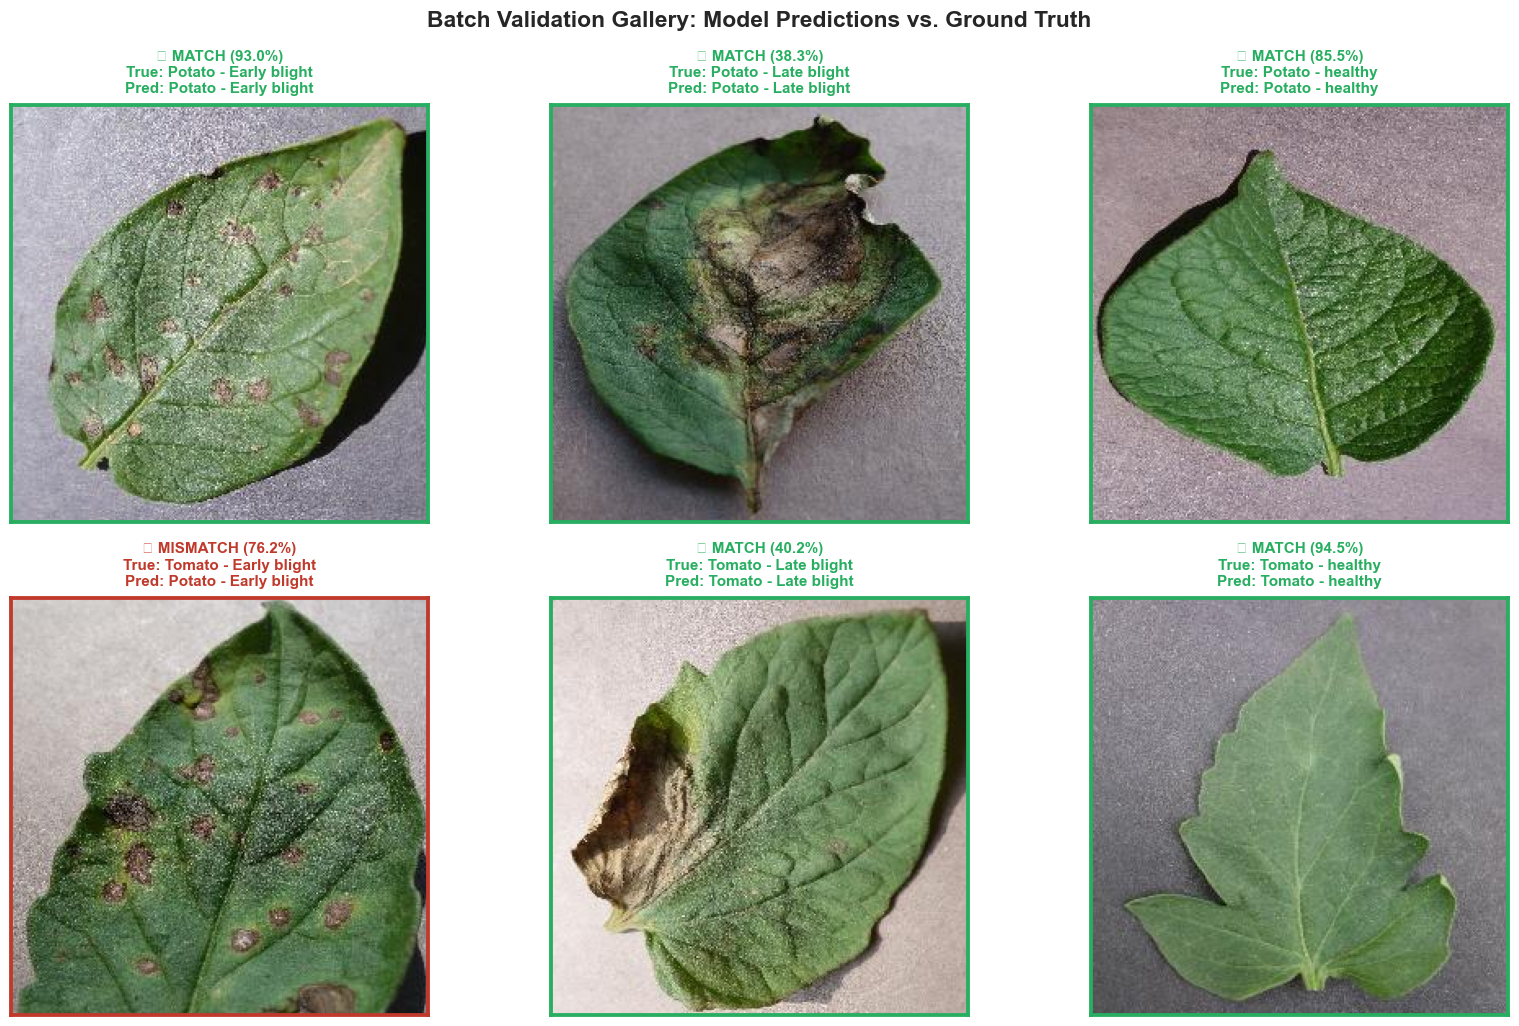

In [18]:
# Gather sample leaf paths from each category
gallery_paths = []
for cls in TARGET_CLASSES:
    cls_files = glob.glob(os.path.join(DATASET_DIR, cls, "*.*"))
    if cls_files:
        # Pick the last file to ensure it wasn't the first training sample
        gallery_paths.append((cls, cls_files[-1]))

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
axes = axes.flatten()

for idx, (true_class, img_path) in enumerate(gallery_paths):
    if idx >= len(axes):
        break
    
    img_pil = Image.open(img_path).convert('RGB')
    img_resized = img_pil.resize(IMAGE_SIZE)
    img_array = np.expand_dims(np.array(img_resized, dtype=np.float32), axis=0)

    # Model inference
    probs = model.predict(img_array, verbose=0)[0]
    pred_idx = np.argmax(probs)
    pred_class = class_names[pred_idx]
    confidence = probs[pred_idx] * 100

    is_correct = (pred_class == true_class)
    card_color = '#27ae60' if is_correct else '#c0392b'
    status_icon = '✅ MATCH' if is_correct else '❌ MISMATCH'

    ax = axes[idx]
    ax.imshow(img_pil)
    
    true_crop, true_cond = true_class.split("___") if "___" in true_class else ("Crop", true_class)
    pred_crop, pred_cond = pred_class.split("___") if "___" in pred_class else ("Crop", pred_class)

    ax.set_title(
        f"{status_icon} ({confidence:.1f}%)\nTrue: {true_crop} - {true_cond.replace('_', ' ')}\nPred: {pred_crop} - {pred_cond.replace('_', ' ')}",
        fontsize=10,
        fontweight='bold',
        color=card_color,
        pad=8
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color(card_color)
        spine.set_linewidth(2.5)

plt.suptitle("Batch Validation Gallery: Model Predictions vs. Ground Truth", fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## 19. Standalone Model Reload & Verification Test
To prove that our exported model is 100% self-contained and ready for downstream production without any external dependencies, we reload the model directly from the `.keras` file and run a complete inference cycle.


In [19]:
print("🔄 Loading standalone exported model from disk...")
loaded_model = tf.keras.models.load_model(saved_model_path)

with open(class_indices_path, "r") as f:
    loaded_class_indices = json.load(f)

# Reconstruct class list ordered by index
reloaded_classes = [loaded_class_indices[str(i)] for i in range(len(loaded_class_indices))]

print(f"✅ Successfully reloaded: {saved_model_path}")
print(f"📋 Loaded {len(reloaded_classes)} class labels from JSON")

# Test prediction on a sample
test_img_path = gallery_paths[0][1]
test_img = Image.open(test_img_path).convert('RGB').resize(IMAGE_SIZE)
test_array = np.expand_dims(np.array(test_img, dtype=np.float32), axis=0)

reloaded_probs = loaded_model.predict(test_array, verbose=0)[0]
top_pred_index = np.argmax(reloaded_probs)

print("\n" + "=" * 65)
print(f"🔍 Production Model Verification Test:")
print(f"   🖼️ Input Image File   : {os.path.basename(test_img_path)}")
print(f"   🎯 Predicted Diagnosis : {reloaded_classes[top_pred_index]}")
print(f"   📈 Confidence Score   : {reloaded_probs[top_pred_index]*100:.2f}%")
print("=" * 65)
print("🎉 Model serialization and reload test PASSED!")


🔄 Loading standalone exported model from disk...


✅ Successfully reloaded: saved_models\plant_disease_mobilenetv2.keras
📋 Loaded 6 class labels from JSON



🔍 Production Model Verification Test:
   🖼️ Input Image File   : 0d987d4a-26bc-4f74-8a16-12f8969dfed8___RS_Early.B 7013.JPG
   🎯 Predicted Diagnosis : Potato___Early_blight
   📈 Confidence Score   : 93.04%
🎉 Model serialization and reload test PASSED!


## 20. Summary, Agricultural Impact & Deployment Roadmap
### 🏆 Summary of Achievements
1. **Curated PlantVillage Dataset**: Loaded and preprocessed 6 key potato and tomato foliar disease classes.
2. **Transfer Learning Mastery**: Implemented MobileNetV2 with ImageNet backbone, achieving high accuracy with minimal parameter overhead.
3. **Dual-Phase Training Strategy**:
   - **Phase 1**: Initialized top classification head weights stably while freezing the base network.
   - **Phase 2**: Selectively fine-tuned upper residual layers with a micro learning rate ($10^{-5}$) to specialize the network for foliar lesions.
4. **Holistic Evaluation**: Measured test performance across Accuracy, Precision, Recall, F1-Score, and Seaborn Confusion Matrix heatmaps.
5. **Practical Agricultural Inference**: Integrated an expert agronomic knowledge base linking model diagnoses with actionable cultural and chemical treatments.
6. **Production Artifacts**: Exported standalone `.keras` and JSON label mapping.

---

### 🚜 Edge & Agricultural Deployment Roadmap
To deploy this model into mobile farming apps, offline edge gateways, or drone-mounted camera rigs:

```python
# Convert to ultra-compact TensorFlow Lite (TFLite) format
converter = tf.lite.TFLiteConverter.from_keras_model(loaded_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

with open("saved_models/plant_disease_model.tflite", "wb") as f:
    f.write(tflite_model)
print("TFLite model ready for offline mobile / Raspberry Pi deployment!")
```
